<a href="https://colab.research.google.com/github/Maysamabufara249/Credit_Risk/blob/main/Credit_Risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1- **Load packages**

In [1]:
# %matplotlib inline helps us to display any graph directily under the cell in Jupyter Notebook

# Dealing with data
import pandas as pd     # We use pandas to handle data that is in the form of a table
import numpy as np      # We use numpy to handle numbers and matrices and math calculations

import matplotlib.pyplot as plt    # Use to create graphs
import seaborn as sns              # Use seaborn to make statistical graphs

from sklearn.preprocessing import LabelEncoder     # Convert category labels into numbers
from sklearn.preprocessing import StandardScaler   # Standardize numerical values to a similar scale
# In scaler, if we have two variables, (Age 18-26) and (Salary 1000-10000), the difference between the numbers is large.
# Therefore, we use (scaler) to set the mean of each variable to (0) and standard deviation to (1), depending on the type of scaler used

from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_classif
# Select the most useful features and relates to the target column -Risk-
# AND without training a predictive model

sns.set_style("whitegrid")                 # Set a clean background for graphs (White with faint grid lines)
plt.rcParams["figure.figsize"] = (10, 5)   # Set the default graph size (width 10 - Height 5)
pd.set_option("display.width", 100)        # Set the width of the displayed table to 100 characters (the text space can hold 100 characters)
pd.set_option("display.max_columns", 20)   # Show up to 20 columns (extra columns may be hidden from display, not deleted)

print("All packages loaded successfully.")

All packages loaded successfully.


# **2- Load the dataset**

In [ ]:
# Read the data from the CSV file, store it in a variable named dataset,
# and print the numbers of rows and columns

DATA_PATH = "german_credit_data.csv"
dataset = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

Dataset loaded: 1000 rows, 10 columns


# **3- Exploratory Data Analysis**

**3.1- Descriptive statistics**

***3.1.1- .head***

In [ ]:
# .head is used if we want to display only the first five rows (0-4) to see if the data is being read correctly or not
# Brackets without a number inside
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [ ]:
# If we want to see fewer or more than 5 rows,
# we put a number inside the brackets in the code,
# and it will display rows equal to the number requested
dataset.head(3)

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good


***3.1.2- .shape***

In [ ]:
# .shape display the dataset size, number of rows and columns
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


***3.1.3- .dtypes***

In [ ]:
# Dispaly the data type of each column in the dataset
# Numeric columns should show int64/float64; text columns show 'object'.
dataset.dtypes

,0
Age,int64
Sex,object
Job,int64
Housing,object
SavingAccounts,object
CheckingAccount,object
CreditAmount,int64
Duration,int64
Purpose,object
Risk,object


***3.1.4- .describe***

In [ ]:
# Dispaly a summary of the numerical columns and dosen't change any data
# Show the count, mean, standard deviation, minimum, maximum, and quartiles of numerical data
# Help identify any problems in the dataset
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [ ]:
# Dispaly a summary of the non-numerical data (Categoral columns)
# identify any problems in the dataset
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


***3.1.5- .isna().sum()***

In [ ]:
# isna().sum() counts missing values per column
# isna().sum() important because it affects the accuracy of the analysis, and some ML algorithms don't understand
# We Can't delete all the rows containing missing value in the dataset because their number is large, and
# therefore we would lose a large part of the data
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


***3.1.6- .value_counts***

In [ ]:
# Count how many good and bad cases are in the target column (Risk)
# (Name: count, dtype: int64) / (Name: proportion, dtype: float64) is extra information displayed automatically by pandas
print(dataset["Risk"].value_counts())
print()
# Calculate the percentage of good and bad cases
# round(3) means rounding the proportions to 3 decimal places
# * 100 converts the proportions into percentages
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


***- Missing values by columns -***

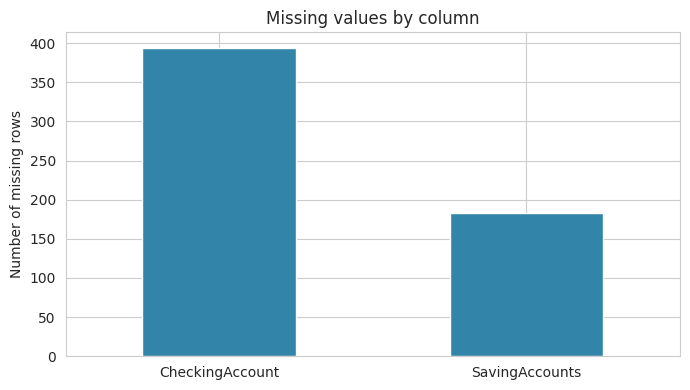

In [ ]:
# Count the missing values in each column
missing_counts = dataset.isna().sum()
# Select the columns with missing values and sort them from highest to lowest
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

# Creat a bar chart showing the missing values for easier understanding
plt.figure(figsize=(7, 4))    # Figure size
missing_counts.plot(kind="bar", color="#3285a8")
plt.title("Missing values by column")    # Chart title
plt.ylabel("Number of missing rows")     # Lable the Y-axis
plt.xticks(rotation=0)        # Keep the X-axis lables horizontal
plt.tight_layout()            # Adjust spacing to make the chart clear
plt.show()                    # Display the chart

# Interpretation: After viewing the graph, it became clear that
# --- only the SavingAccounts and the ChekingAccounts had missing value ---


### **3.2- Data visualization**

***3.2.1- Univariate plots***

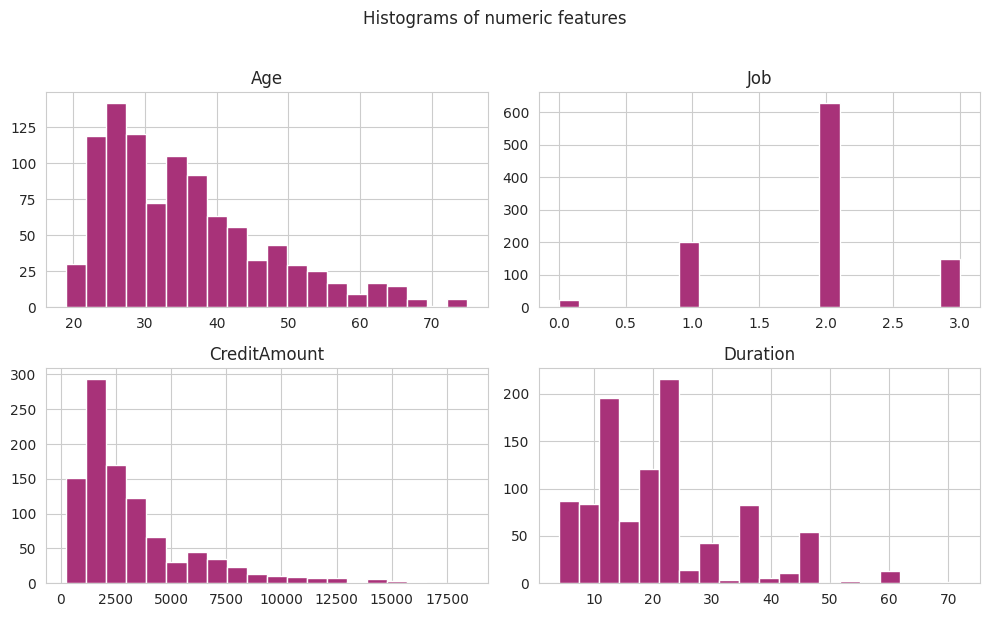

In [ ]:
# We use histograms for numerical columns to show the shape of each distribution
# Select the columns to visualization
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

# Select the properties of a histogram
dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#a83279", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)  # Add a main title above all histograms
plt.tight_layout()    # Adjust tha spacing between histogram
plt.show()            # Display the histogram

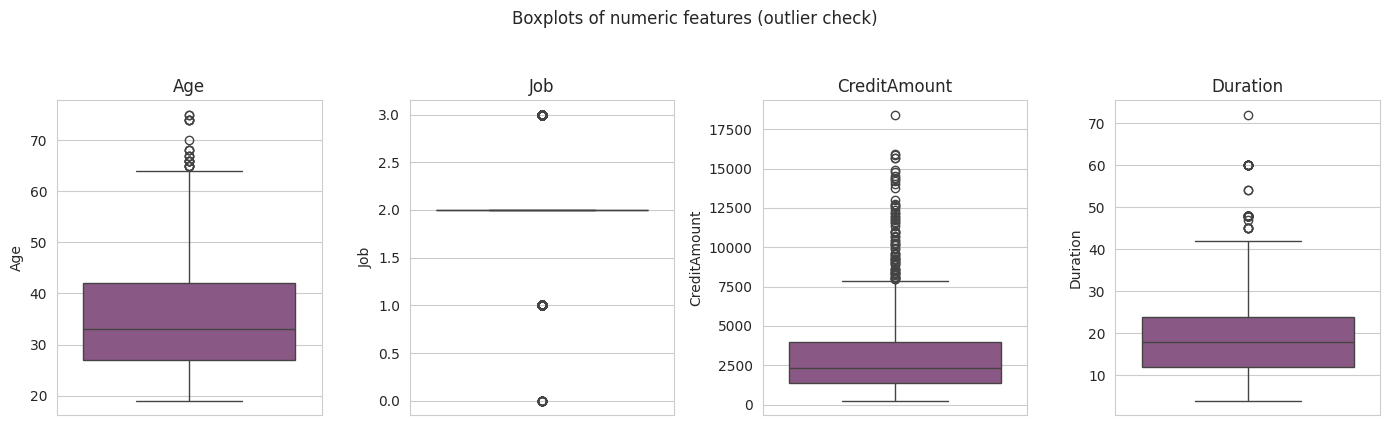

In [ ]:
# Boxplots are used to detect outliers - data values that are far from the values of all other data -
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#91508b")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()

# Interpretation: CreditAmount has the most outliers, then Duration

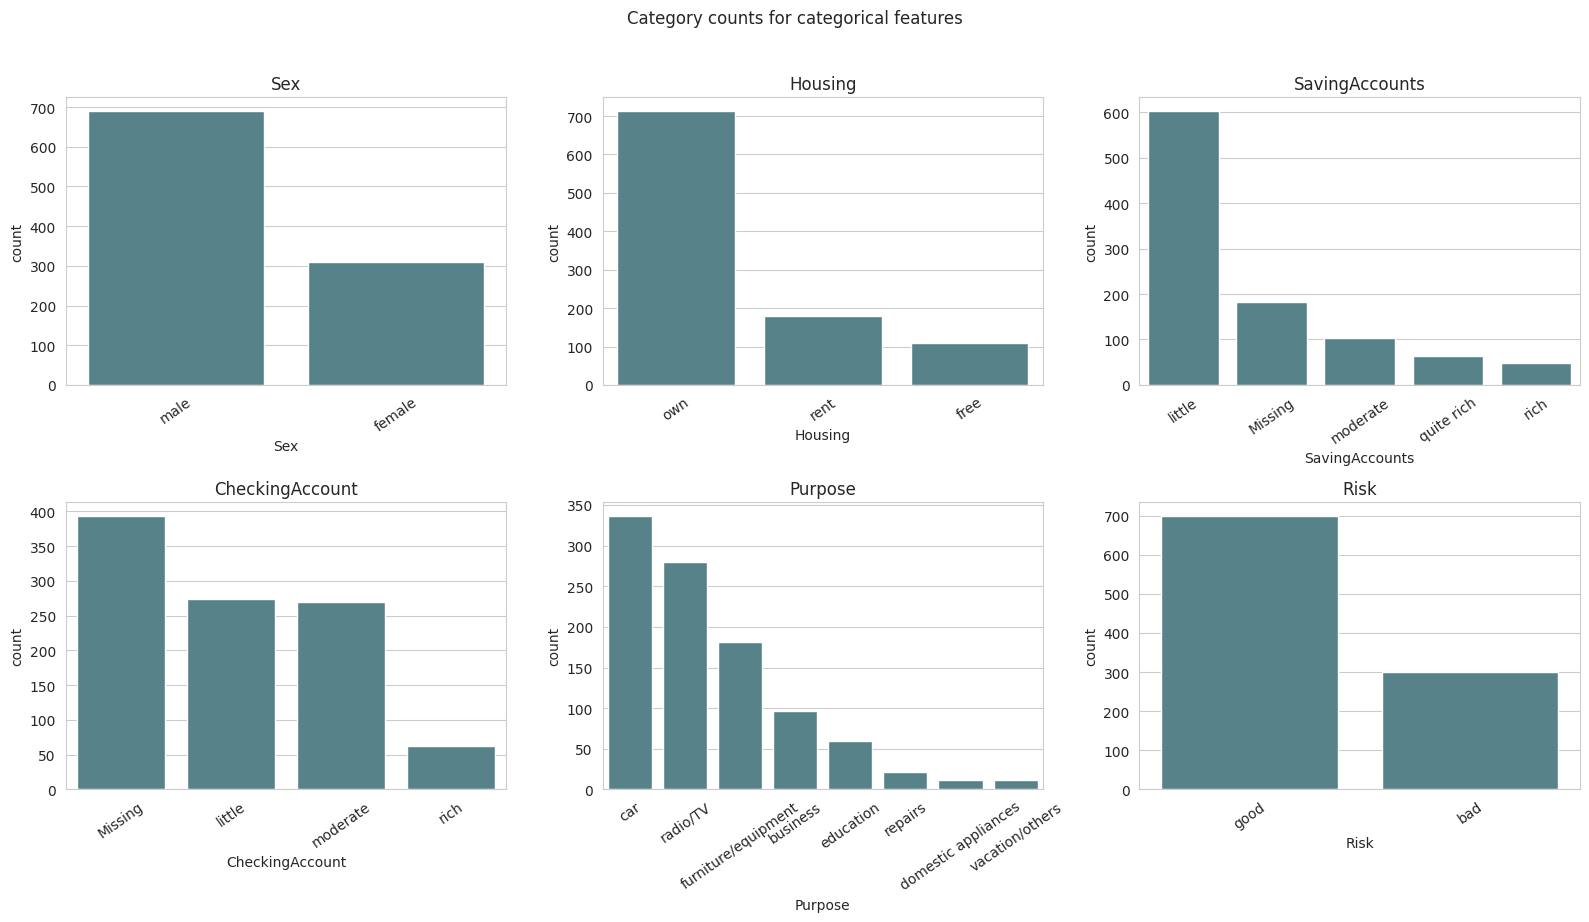

In [ ]:
# Count plots are used for categorical columns to see how often each category is repeated
# Select the categorical columns to visualize
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):
    # Show missing values ​​as a separate category and label it 'missing'
    col_data = dataset[col].fillna("Missing")
    # order= Sort categories from most to least frequent
    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#508891")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()

***3.2.2- Multivariate plots***

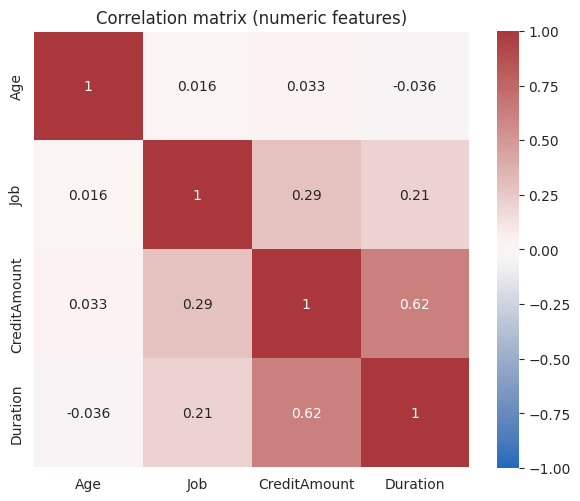

In [ ]:
# Use a heatmap to show the correlation between numerical features, that is, the strength of the relationships between these numerical features.
# Values close to +1 or -1 mean two features move together strongly
# values near 0 mean little to no linear relationship.
plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

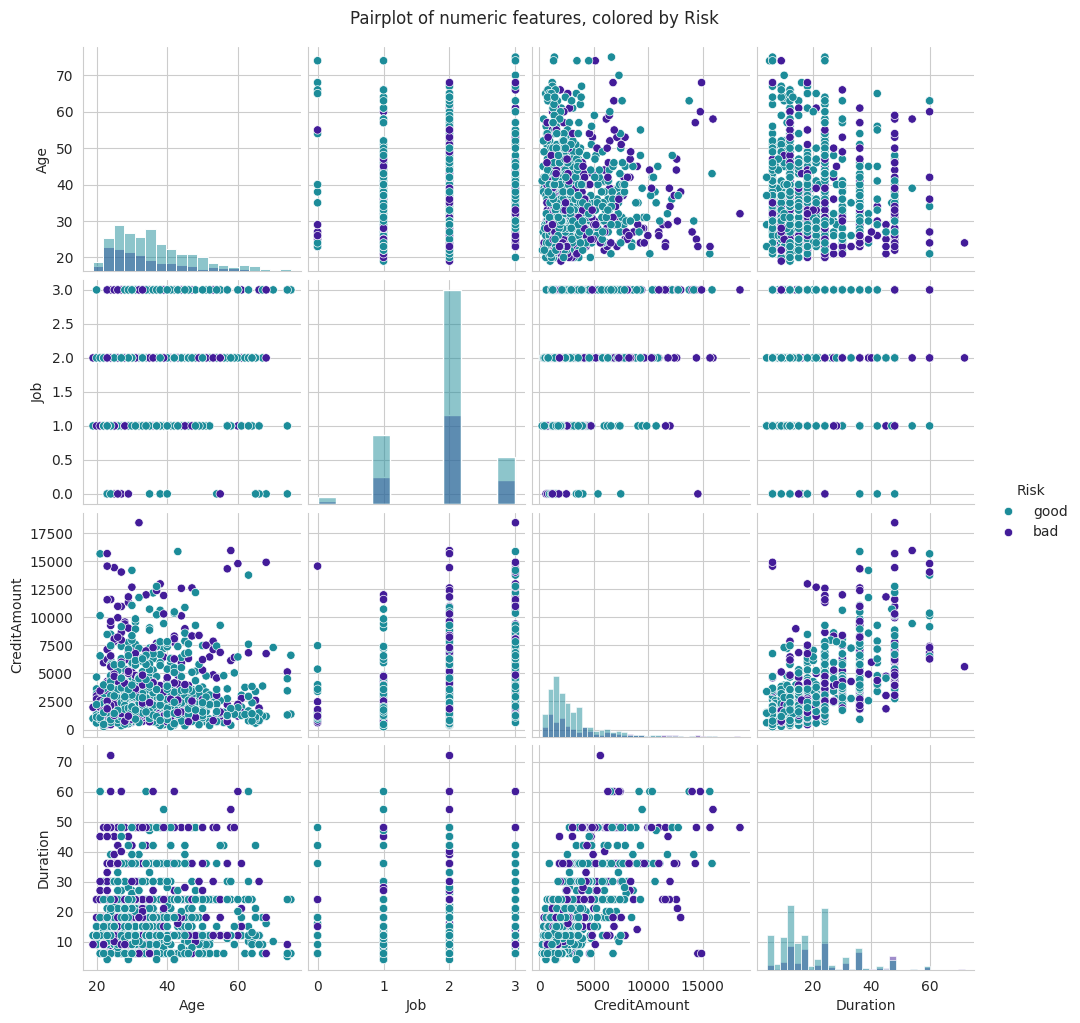

In [ ]:
# Use a pairplot to show relationships between numerical features and compare good and bad risk cases
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#1c8c99", "bad": "#431c99"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

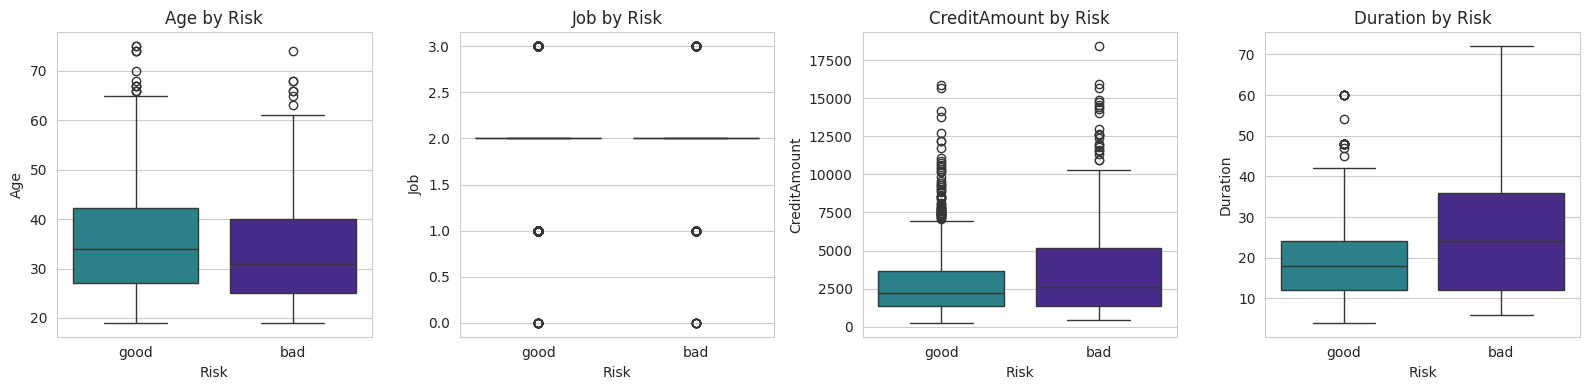

In [ ]:
# Boxplots are used to compare the distribution of numerical variables
# between customers rated good and customer rated bad.
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#1c8c99", "bad": "#431c99"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()

# Interpretation: Bad risk applicants tend to have higher CreditAmount and longer Duration


# **4- Data Preparation**

**4.1- Data cleaning**

***4.1.1- Handling missing values***

In [ ]:
# Create a copy of the original dataset so that it remains unchanged and can be referred to if needed.
df_clean = dataset.copy()

# Replace missing values ​​in the SavingAccounts and CheckingAccount with the word "none".
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# Check the dataset after cleaning and ensure that no missing values ​​remain.
print("Remaining missing values:\n")
print(df_clean.isna().sum())


# Interpretation: It turned out that the result for the variables is zero,
# because we replaced the missing values ​​with the word "none";
# consequently, they are no longer considered missing values.

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


**4.2- Data transformation**

***4.2.1- Encoding***

In [ ]:
# Encode categorical columns : Converting categorical data into numbers,
# as most machine learning models require data to be in numerical form.

df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


***4.2.2- Scaling***

In [ ]:
# Scale numeric columns : Scaling numerical variables to a standardized scale
# Converting them into new values ​​such that the (Mean ≈ 0) and the (Standard Deviation ≈ 1).
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

# Compare a couple of rows before vs. after scaling, to see what changed.
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


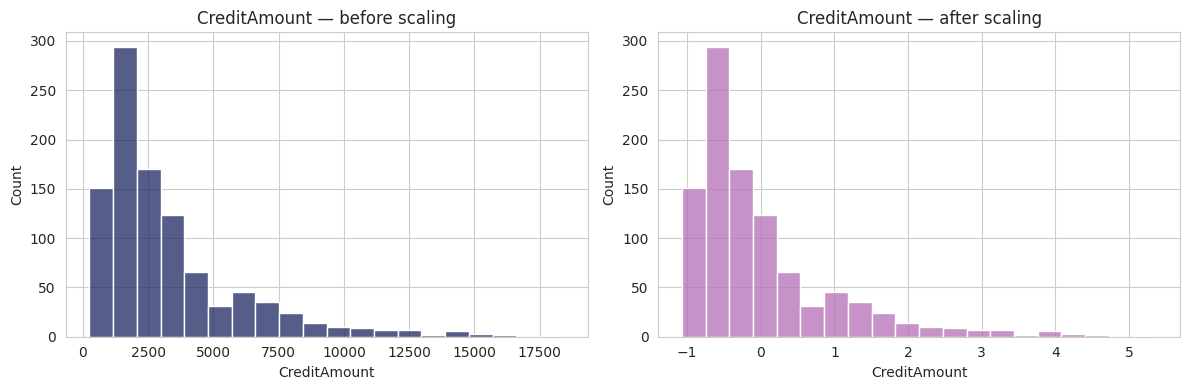

In [ ]:
# Compare the distribution before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#1E2761")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#b46eb5")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()

# Interpretation: Scaling changes the values on the X-axis,
# but the shape of the distribution remains the same.
# CreditAmount is still right-skewed after scaling.

# **5- Feature Selection**

In [ ]:
# Feature selection: Which features in our data might be most useful for predicting,
# whether a customer is "good" or "bad"?
# Separate the features (X) and the target (y).
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

# SelectKBest is a feature selection method that ranks features based on their scores and selects the best ones.
# f_classif uses the ANOVA F-test to measure how much each feature differs between target classes.
selector = SelectKBest(score_func=f_classif, k="all")   # k="all" : Calculating scores for all features, without removing any of them for the time being.
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores

,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


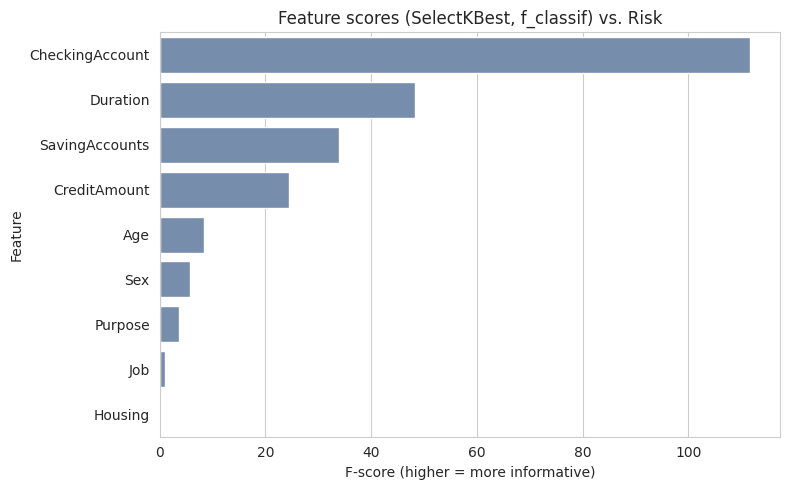

In [ ]:
# Visualize the feature scores.
# The purpose of the bar chart is to compare feature scores;
# in order to identify which variables exhibit the greatest differences
# between the two risk groups: "good" and "bad".
plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#6e8cb5")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()

# Interpretation: Features with higher F-scores show stronger
# differences between the good and bad Risk groups.
# These features may be more useful for predicting credit risk.